# 06 · Data quality and validation
Everything that was excluded, flagged or could not be verified, in one place.

| | |
|---|---|
| **Objective** | Show everything that was excluded, flagged or could not be verified. |
| **Dataset** | dq_* tables, live checks, tests. |
| **Business question** | Can the numbers be trusted, and where are the limits? |
| **Method** | Integrity, validity, unit, consistency and external-validation checks. |
| **Output** | Data-quality summary, issue log, validation chart, test results. |
| **Key finding** | All live checks pass; district totals are within 10% of official estimates for 4 of 8 crops in the provisional 2019-20 year. |

In [1]:
import sys, sqlite3, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import RAW, CURATED, PROC, RESULTS, FIGURES, DB_PATH, connect_ro
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
BLUE, ORANGE, AQUA, YELLOW, PINK, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948", "#9aa19c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 11})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight"); plt.show()
con = connect_ro()

## Live checks
Recomputed by `src/dq_report.py` on every pipeline run (also written to `docs/DATA_QUALITY.md` and the README).

In [2]:
pd.read_csv(RESULTS / "dq_summary.csv")

,area,check,value,expected,status,note
0,Integrity,Foreign-key violations,0,0,PASS,NaN
1,Integrity,Duplicate production keys (district x crop x y...,0,0,PASS,NaN
2,Integrity,Duplicate district x crop x year rows,0,0,PASS,NaN
3,Integrity,Duplicate MSP crop x year,0,0,PASS,NaN
4,Integrity,Duplicate mandi quotes (dataset x market x cro...,0,0,PASS,exact duplicates are dropped at load
5,Integrity,Missing crop_id in fact tables,0,0,PASS,NaN
6,Validity,Negative area or production,0,0,PASS,NaN
7,Validity,Non-positive modal prices left in analysis,0,0,PASS,NaN
8,Validity,Mandi quotes excluded (<=0 or >5x / <1/5 of me...,310,documented,PASS,"0.29% of 106,885 quotes"
9,Validity,Quotes flagged: min/modal/max inconsistent,464,documented,PASS,kept for modal; no spread


## Issues found and how each was handled

In [3]:
pd.read_sql("select domain, issue, action, n_rows, detail from dq_issues", con)

,domain,issue,action,n_rows,detail
0,Production (APY),Crop year 2020 reported by only 13 districts (...,excluded,219,NaN
1,Production (APY),Duplicate district-crop-year-season key with c...,excluded (both rows),114,NaN
2,Production (APY),Implausible yield (above agronomic ceiling for...,excluded,9,NaN
3,Mandi prices,modal <= 0,excluded,45,NaN
4,Mandi prices,modal >5x or <1/5 of commodity median,excluded,265,NaN
5,Mandi prices,min/modal/max inconsistent (spread not computed),flag,464,NaN
6,Mandi prices,Repeated quote for the same market x commodity...,dropped before load (FAQ grade kept),46,AGMARKNET daily snapshot 30-Sep-2024
7,Mandi prices,Repeated quote for the same market x commodity...,dropped before load (FAQ grade kept),9929,AGMARKNET daily Jul-Sep 2026
8,MSP,CMO vs PIB mismatch for Bajra 2013-14 (1310.0 ...,use PIB 1250,1,CMO 1310 equals the maize MSP (copy error in C...
9,MSP,CMO vs PIB mismatch for Sesamum 2013-14 (4500....,keep CMO 4500,1,PIB value 2500 breaks the series 4200 (2012) -...


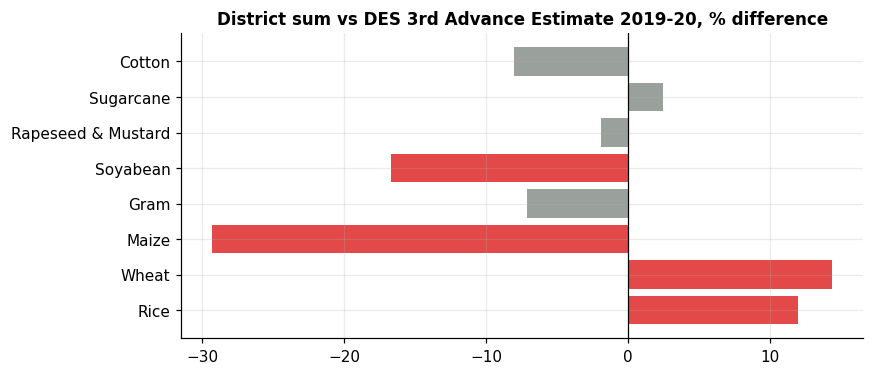

,crop_name,dataset_value,official_value,unit,diff_pct,status
0,Rice,132.11,117.94,million tonnes,12.0,divergent (>10%)
1,Wheat,122.61,107.18,million tonnes,14.4,divergent (>10%)
2,Maize,20.47,28.98,million tonnes,-29.3,divergent (>10%)
3,Gram,10.13,10.90,million tonnes,-7.1,consistent (within 10%)
4,Soyabean,10.19,12.24,million tonnes,-16.7,divergent (>10%)
5,Rapeseed & Mustard,8.54,8.70,million tonnes,-1.9,consistent (within 10%)
6,Sugarcane,367.21,358.14,million tonnes,2.5,consistent (within 10%)
7,Cotton,33.17,36.05,million bales (170 kg),-8.0,consistent (within 10%)


In [4]:
v = pd.read_sql("select * from dq_validation", con)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(v.crop_name, v.diff_pct, color=[RED if abs(x) > 10 else GREY for x in v.diff_pct]); ax.axvline(0, color="k", lw=.8)
ax.set_title("District sum vs DES 3rd Advance Estimate 2019-20, % difference"); save(fig, "06_validation")
v[["crop_name", "dataset_value", "official_value", "unit", "diff_pct", "status"]]

In [5]:
cov = pd.read_sql("select member, metric, value from dq_coverage where domain in ('Production','Valuation') and dimension='crop_year'", con)
cov.pivot(index="member", columns="metric", values="value").round(3)

metric,districts,rows,share_rows_msp_valued
member,,,
1997,470.0,6772.0,NaN
1998,547.0,9120.0,NaN
1999,564.0,9597.0,NaN
2000,550.0,9518.0,NaN
2001,549.0,9520.0,NaN
2002,570.0,9901.0,NaN
2003,586.0,10228.0,NaN
2004,590.0,9818.0,0.836
2005,593.0,9696.0,0.841


In [6]:
pd.read_sql("select source_id, dataset, publisher, coverage, reliability_note from ref_sources", con)

,source_id,dataset,publisher,coverage,reliability_note
0,APY,"District-wise, season-wise crop production sta...","DES, Ministry of Agriculture & FW (via data.go...",1997-98 to 2019-20,District sums diverge from DES all-India estim...
1,MSP,Minimum Support Prices / FRP,"CACP & DA&FW (PIB, DES, data.gov.in)",2002-03 to 2024-25,2003-04 not available; bonus treatment varies ...
2,COC,Cost of cultivation / production - principal c...,DES Cost of Cultivation Scheme (CACP),2008-09 to 2013-14,Only 10 crops x 5 states each; no projection p...
3,CMO,Maharashtra APMC monthly arrivals & prices,Govt. of Maharashtra APMC data (OGD hackathon ...,Sep-2014 to Nov-2016,Single state; original publisher page not re-v...
4,AGM,Current Daily Price of Various Commodities fro...,AGMARKNET / DMI via data.gov.in,30-Sep-2024 (single day),One-day cross-section; no arrivals quantity
5,AGM26,Current Daily Price of Various Commodities fro...,AGMARKNET / DMI via data.gov.in API,21-Jul-2026 to 24-Sep-2026,No arrival quantities; exact duplicate rows dr...
6,CPI,"Consumer price index, India (2010 = 100)",World Bank WDI FP.CPI.TOTL (IMF IFS),2000-2025,"Headline CPI, not a farm-specific deflator"
7,IMD,Sub-divisional monthly rainfall 1901-2015,India Meteorological Department (via data.gov.in),1901-2015,Subdivision != state; normal = 1951-2000 mean ...
8,PIB_AE,Advance estimates of production 2019-20,DA&FW via PIB,2019-20,NaN


In [7]:
pd.read_sql("select msp_key, crop_year_label, msp_effective, source_id, source_url, note from fact_msp where verification='secondary'", con)

,msp_key,crop_year_label,msp_effective,source_id,source_url,note
0,Barley,2026-27,2286.0,NEWS_RB_2027,https://www.business-standard.com/economy/news...,RMS 2027-28 announced 30-Sep-2026; secondary s...
1,Gram,2026-27,5958.0,NEWS_RB_2027,https://www.business-standard.com/economy/news...,RMS 2027-28 announced 30-Sep-2026; secondary s...
2,Jute,2017-18,3500.0,NEWS_JUTE_2018,https://www.business-standard.com/amp/article/...,Derived: 2018-19 MSP of Rs 3700 was a Rs 200 i...
3,Masur,2026-27,7390.0,NEWS_RB_2027,https://www.business-standard.com/economy/news...,RMS 2027-28 announced 30-Sep-2026; secondary s...
4,Mustard,2026-27,6613.0,NEWS_RB_2027,https://www.business-standard.com/economy/news...,RMS 2027-28 announced 30-Sep-2026; secondary s...
5,Safflower,2026-27,7215.0,NEWS_RB_2027,https://www.business-standard.com/economy/news...,RMS 2027-28 announced 30-Sep-2026; secondary s...
6,Sugarcane,2019-20,275.0,NEWS_FRP_2019,https://www.business-standard.com/article/pti-...,FRP 2019-20 reported unchanged at Rs 275 (seco...
7,Wheat,2026-27,2610.0,NEWS_RB_2027,https://www.business-standard.com/economy/news...,RMS 2027-28 announced 30-Sep-2026; secondary s...


## Automated tests
`tests/test_pipeline.py` has 15 tests: unit factors, gross value arithmetic, valuation window, profit only where cost exists, marketing-season rule, MSP spot checks (including 2026), price sanity, SQL answers equal to the pandas answers, and the loader for newer production files.

In [8]:
import subprocess; print(subprocess.run([sys.executable, '-m', 'pytest', '-q', '--color=no', '-p', 'no:cacheprovider', 'tests'], cwd=ROOT, capture_output=True, text=True).stdout[-400:])

...............                                                          [100%]
15 passed in 1.34s



## Conclusion
Known issues are fixed or flagged, never hidden.

## Limitations
External validation is limited to one provisional year.

## Next steps
Validate against final DES estimates once newer production data are added.